In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve
)

warnings.filterwarnings("ignore")

plt.style.use("ggplot")

In [2]:
IMAGE_SIZE = (224,224)

BATCH_SIZE = 32

MODEL_PATH = "../models/final_model.keras"

TEST_DIR = "../data/test"

RESULTS_DIR = "../results"

os.makedirs(RESULTS_DIR, exist_ok=True)

In [3]:
#####################################################
# Clinical Cost Settings
#####################################################

FALSE_POSITIVE_COST = 1

FALSE_NEGATIVE_COST = 10

In [4]:
model = load_model(MODEL_PATH)

print("Model Loaded Successfully")

Model Loaded Successfully


In [5]:
test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_generator = test_datagen.flow_from_directory(

    TEST_DIR,

    target_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    class_mode="binary",

    shuffle=False

)

Found 624 images belonging to 2 classes.


In [6]:
class_names = list(test_generator.class_indices.keys())

print(class_names)

print(test_generator.class_indices)

['NORMAL', 'PNEUMONIA']
{'NORMAL': 0, 'PNEUMONIA': 1}


In [7]:
y_true = test_generator.classes

y_prob = model.predict(

    test_generator,

    verbose=1

).flatten()

print("Total Images :",len(y_true))

print("Prediction Shape :",y_prob.shape)

20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 390ms/step
Total Images : 624
Prediction Shape : (624,)


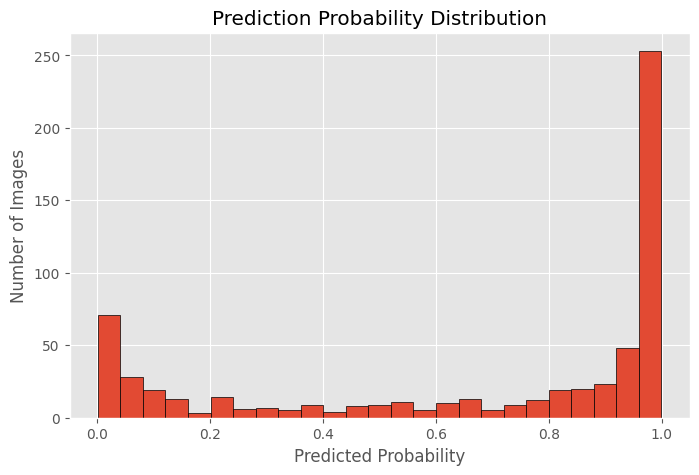

In [8]:
plt.figure(figsize=(8,5))

plt.hist(

    y_prob,

    bins=25,

    edgecolor="black"

)

plt.title("Prediction Probability Distribution")

plt.xlabel("Predicted Probability")

plt.ylabel("Number of Images")

plt.show()

In [9]:
probability_df = pd.DataFrame({

    "True_Label": y_true,

    "Probability": y_prob

})

probability_df.head()

,True_Label,Probability
0,0,0.003863
1,0,0.029388
2,0,0.033258
3,0,0.459244
4,0,0.110680


In [10]:
#####################################################
# Default Threshold Prediction
#####################################################

DEFAULT_THRESHOLD = 0.50

y_pred_default = (
    y_prob >= DEFAULT_THRESHOLD
).astype(int)

print("Threshold :", DEFAULT_THRESHOLD)
print("Total Predictions :", len(y_pred_default))

Threshold : 0.5
Total Predictions : 624


In [11]:
from sklearn.metrics import classification_report

print("="*60)
print("BASELINE CLASSIFICATION REPORT")
print("="*60)

print(

    classification_report(

        y_true,

        y_pred_default,

        target_names=class_names

    )

)

BASELINE CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL       0.93      0.76      0.84       234
   PNEUMONIA       0.87      0.96      0.92       390

    accuracy                           0.89       624
   macro avg       0.90      0.86      0.88       624
weighted avg       0.89      0.89      0.89       624



In [12]:
cm = confusion_matrix(

    y_true,

    y_pred_default

)

cm

array([[179,  55],
       [ 14, 376]])

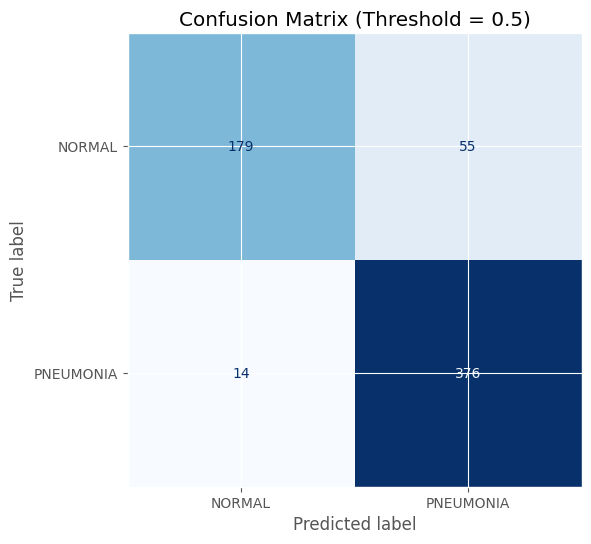

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6,6))

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=class_names

)

disp.plot(

    cmap="Blues",

    ax=ax,

    colorbar=False

)

plt.title(

    f"Confusion Matrix (Threshold = {DEFAULT_THRESHOLD})"

)

plt.tight_layout()

plt.show()

In [14]:
accuracy = accuracy_score(
    y_true,
    y_pred_default
)

precision = precision_score(
    y_true,
    y_pred_default
)

recall = recall_score(
    y_true,
    y_pred_default
)

f1 = f1_score(
    y_true,
    y_pred_default
)

In [15]:
tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn)

specificity = tn / (tn + fp)

print("Sensitivity :", sensitivity)

print("Specificity :", specificity)

Sensitivity : 0.9641025641025641
Specificity : 0.7649572649572649


In [16]:
clinical_cost = (

    FALSE_POSITIVE_COST * fp

    +

    FALSE_NEGATIVE_COST * fn

)

print("Clinical Cost :", clinical_cost)

Clinical Cost : 195


In [17]:
baseline_metrics = pd.DataFrame({

    "Metric":[

        "Accuracy",

        "Precision",

        "Recall",

        "F1 Score",

        "Sensitivity",

        "Specificity",

        "False Positives",

        "False Negatives",

        "Clinical Cost"

    ],

    "Value":[

        accuracy,

        precision,

        recall,

        f1,

        sensitivity,

        specificity,

        fp,

        fn,

        clinical_cost

    ]

})

baseline_metrics

,Metric,Value
0,Accuracy,0.889423
1,Precision,0.872390
2,Recall,0.964103
3,F1 Score,0.915956
4,Sensitivity,0.964103
5,Specificity,0.764957
6,False Positives,55.000000
7,False Negatives,14.000000
8,Clinical Cost,195.000000


In [18]:
print("="*60)
print("BASELINE PERFORMANCE")
print("="*60)

print(f"Accuracy       : {accuracy:.4f}")
print(f"Precision      : {precision:.4f}")
print(f"Recall         : {recall:.4f}")
print(f"F1 Score       : {f1:.4f}")
print(f"Sensitivity    : {sensitivity:.4f}")
print(f"Specificity    : {specificity:.4f}")
print(f"False Positive : {fp}")
print(f"False Negative : {fn}")
print(f"Clinical Cost  : {clinical_cost}")

BASELINE PERFORMANCE
Accuracy       : 0.8894
Precision      : 0.8724
Recall         : 0.9641
F1 Score       : 0.9160
Sensitivity    : 0.9641
Specificity    : 0.7650
False Positive : 55
False Negative : 14
Clinical Cost  : 195


In [19]:
#####################################################
# Generate Thresholds
#####################################################

thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

print("Total Thresholds :", len(thresholds))
print(thresholds)

Total Thresholds : 17
[0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7  0.75
 0.8  0.85 0.9 ]


In [20]:
#####################################################
# Threshold Evaluation
#####################################################

results = []

for threshold in thresholds:

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred
    )

    f1 = f1_score(
        y_true,
        y_pred
    )

    sensitivity = recall

    specificity = tn / (tn + fp)

    clinical_cost = (

        FALSE_POSITIVE_COST * fp

        +

        FALSE_NEGATIVE_COST * fn

    )

    results.append({

        "Threshold": threshold,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1 Score": f1,

        "Sensitivity": sensitivity,

        "Specificity": specificity,

        "False Positives": fp,

        "False Negatives": fn,

        "Clinical Cost": clinical_cost

    })

results = pd.DataFrame(results)

results

,Threshold,Accuracy,Precision,Recall,F1 Score,Sensitivity,Specificity,False Positives,False Negatives,Clinical Cost
0,0.10,0.799679,0.757282,1.000000,0.861878,1.000000,0.465812,125,0,125
1,0.15,0.831731,0.789047,0.997436,0.881087,0.997436,0.555556,104,1,114
2,0.20,0.836538,0.793878,0.997436,0.884091,0.997436,0.568376,101,1,111
3,0.25,0.857372,0.816842,0.994872,0.897110,0.994872,0.628205,87,2,107
4,0.30,0.866987,0.828694,0.992308,0.903151,0.992308,0.658120,80,3,110
5,0.35,0.878205,0.841304,0.992308,0.910588,0.992308,0.688034,73,3,103
6,0.40,0.879808,0.850780,0.979487,0.910608,0.979487,0.713675,67,8,147
7,0.45,0.879808,0.853933,0.974359,0.910180,0.974359,0.722222,65,10,165
8,0.50,0.889423,0.872390,0.964103,0.915956,0.964103,0.764957,55,14,195
9,0.55,0.891026,0.881517,0.953846,0.916256,0.953846,0.786325,50,18,230


In [21]:
best_accuracy = results.loc[
    results["Accuracy"].idxmax()
]

best_accuracy

Threshold            0.750000
Accuracy             0.913462
Precision            0.944444
Recall               0.915385
F1 Score             0.929688
Sensitivity          0.915385
Specificity          0.910256
False Positives     21.000000
False Negatives     33.000000
Clinical Cost      351.000000
Name: 13, dtype: float64

In [22]:
best_f1 = results.loc[
    results["F1 Score"].idxmax()
]

best_f1

Threshold            0.750000
Accuracy             0.913462
Precision            0.944444
Recall               0.915385
F1 Score             0.929688
Sensitivity          0.915385
Specificity          0.910256
False Positives     21.000000
False Negatives     33.000000
Clinical Cost      351.000000
Name: 13, dtype: float64

In [23]:
best_cost = results.loc[
    results["Clinical Cost"].idxmin()
]

best_cost

Threshold            0.350000
Accuracy             0.878205
Precision            0.841304
Recall               0.992308
F1 Score             0.910588
Sensitivity          0.992308
Specificity          0.688034
False Positives     73.000000
False Negatives      3.000000
Clinical Cost      103.000000
Name: 5, dtype: float64

In [25]:
best_recall = results.loc[
    results["Recall"].idxmax()
]

best_recall

Threshold            0.100000
Accuracy             0.799679
Precision            0.757282
Recall               1.000000
F1 Score             0.861878
Sensitivity          1.000000
Specificity          0.465812
False Positives    125.000000
False Negatives      0.000000
Clinical Cost      125.000000
Name: 0, dtype: float64

In [26]:
summary = pd.DataFrame({

    "Criterion":[

        "Best Accuracy",

        "Best F1",

        "Highest Recall",

        "Lowest Clinical Cost"

    ],

    "Threshold":[

        best_accuracy["Threshold"],

        best_f1["Threshold"],

        best_recall["Threshold"],

        best_cost["Threshold"]

    ],

    "Accuracy":[

        best_accuracy["Accuracy"],

        best_f1["Accuracy"],

        best_recall["Accuracy"],

        best_cost["Accuracy"]

    ],

    "Precision":[

        best_accuracy["Precision"],

        best_f1["Precision"],

        best_recall["Precision"],

        best_cost["Precision"]

    ],

    "Recall":[

        best_accuracy["Recall"],

        best_f1["Recall"],

        best_recall["Recall"],

        best_cost["Recall"]

    ],

    "F1":[

        best_accuracy["F1 Score"],

        best_f1["F1 Score"],

        best_recall["F1 Score"],

        best_cost["F1 Score"]

    ]

})

summary.round(4)

,Criterion,Threshold,Accuracy,Precision,Recall,F1
0,Best Accuracy,0.75,0.9135,0.9444,0.9154,0.9297
1,Best F1,0.75,0.9135,0.9444,0.9154,0.9297
2,Highest Recall,0.10,0.7997,0.7573,1.0000,0.8619
3,Lowest Clinical Cost,0.35,0.8782,0.8413,0.9923,0.9106


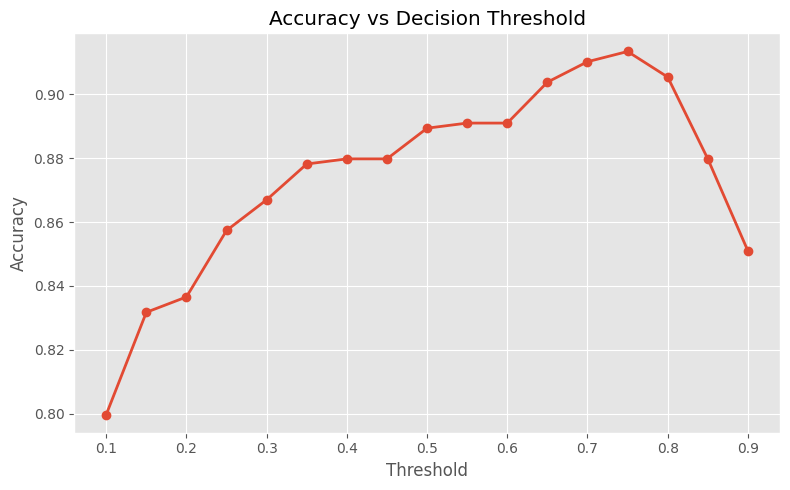

In [27]:
plt.figure(figsize=(8,5))

plt.plot(
    results["Threshold"],
    results["Accuracy"],
    marker="o",
    linewidth=2
)

plt.xlabel("Threshold")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Decision Threshold")

plt.grid(True)

plt.tight_layout()

plt.show()

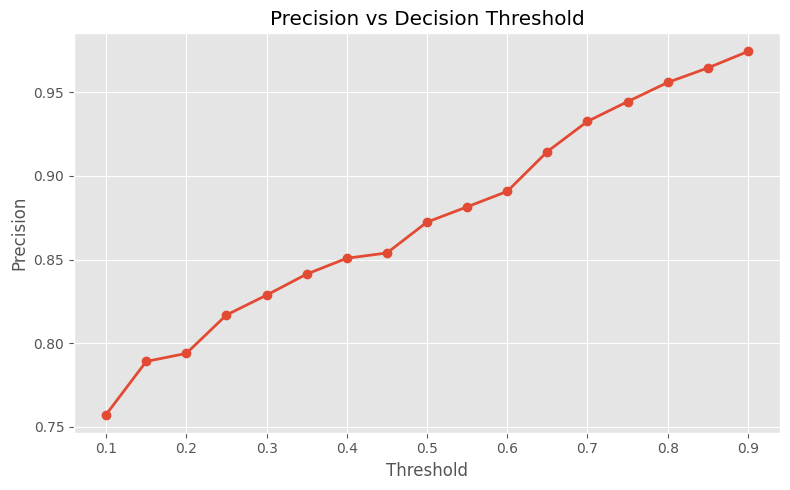

In [28]:
plt.figure(figsize=(8,5))

plt.plot(
    results["Threshold"],
    results["Precision"],
    marker="o",
    linewidth=2
)

plt.xlabel("Threshold")
plt.ylabel("Precision")
plt.title("Precision vs Decision Threshold")

plt.grid(True)

plt.tight_layout()

plt.show()

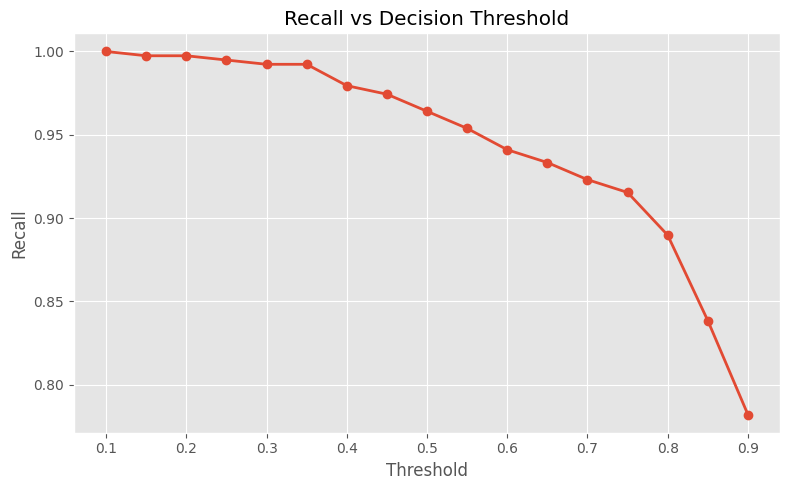

In [29]:
plt.figure(figsize=(8,5))

plt.plot(
    results["Threshold"],
    results["Recall"],
    marker="o",
    linewidth=2
)

plt.xlabel("Threshold")
plt.ylabel("Recall")

plt.title("Recall vs Decision Threshold")

plt.grid(True)

plt.tight_layout()



plt.show()

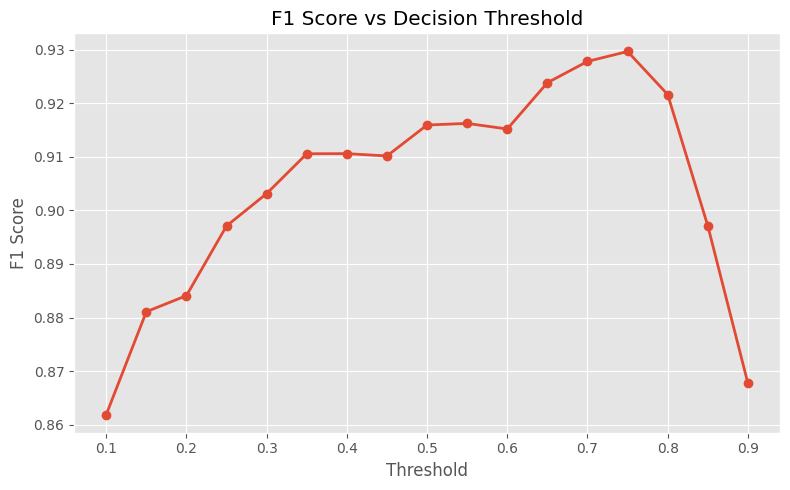

In [30]:
plt.figure(figsize=(8,5))

plt.plot(
    results["Threshold"],
    results["F1 Score"],
    marker="o",
    linewidth=2
)

plt.xlabel("Threshold")
plt.ylabel("F1 Score")

plt.title("F1 Score vs Decision Threshold")

plt.grid(True)

plt.tight_layout()

plt.show()

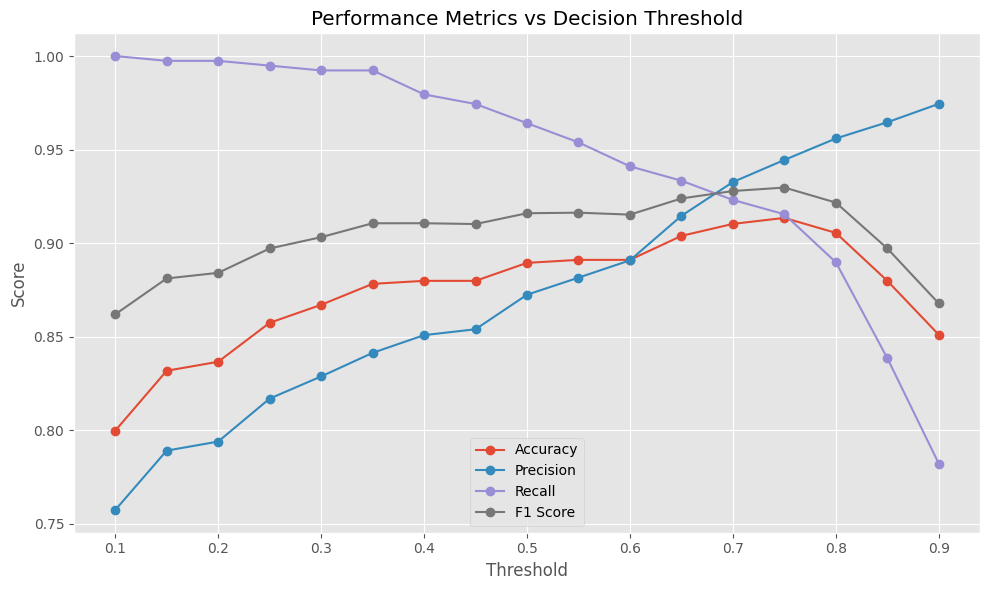

In [31]:
plt.figure(figsize=(10,6))

plt.plot(
    results["Threshold"],
    results["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    results["Threshold"],
    results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    results["Threshold"],
    results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    results["Threshold"],
    results["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Threshold")
plt.ylabel("Score")

plt.title("Performance Metrics vs Decision Threshold")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

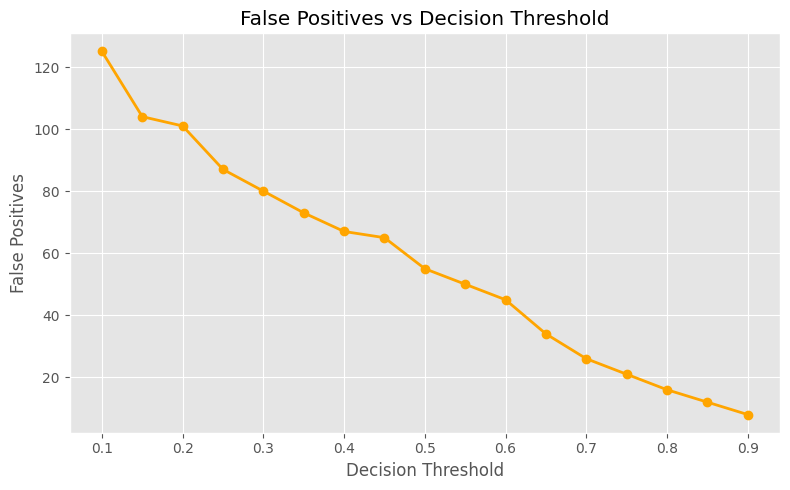

In [32]:
#####################################################
# False Positives vs Threshold
#####################################################

plt.figure(figsize=(8,5))

plt.plot(
    results["Threshold"],
    results["False Positives"],
    marker="o",
    linewidth=2,
    color="orange"
)

plt.xlabel("Decision Threshold")
plt.ylabel("False Positives")

plt.title("False Positives vs Decision Threshold")

plt.grid(True)

plt.tight_layout()

plt.show()

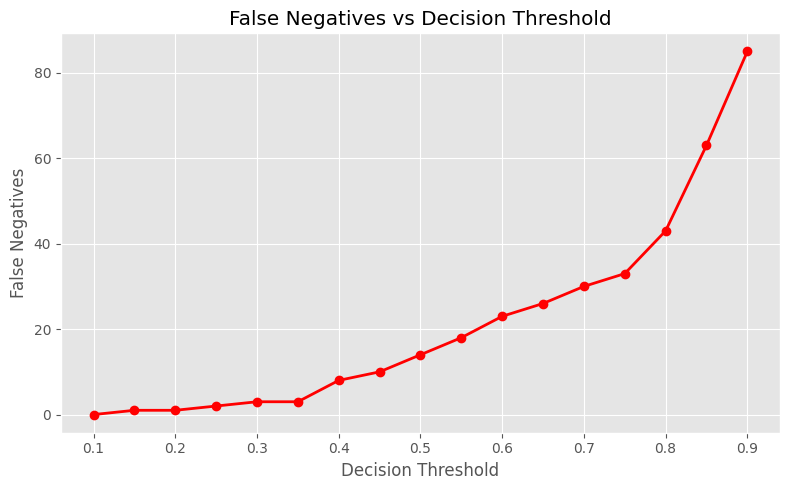

In [33]:
#####################################################
# False Negatives vs Threshold
#####################################################

plt.figure(figsize=(8,5))

plt.plot(
    results["Threshold"],
    results["False Negatives"],
    marker="o",
    linewidth=2,
    color="red"
)

plt.xlabel("Decision Threshold")
plt.ylabel("False Negatives")

plt.title("False Negatives vs Decision Threshold")

plt.grid(True)

plt.tight_layout()

plt.show()

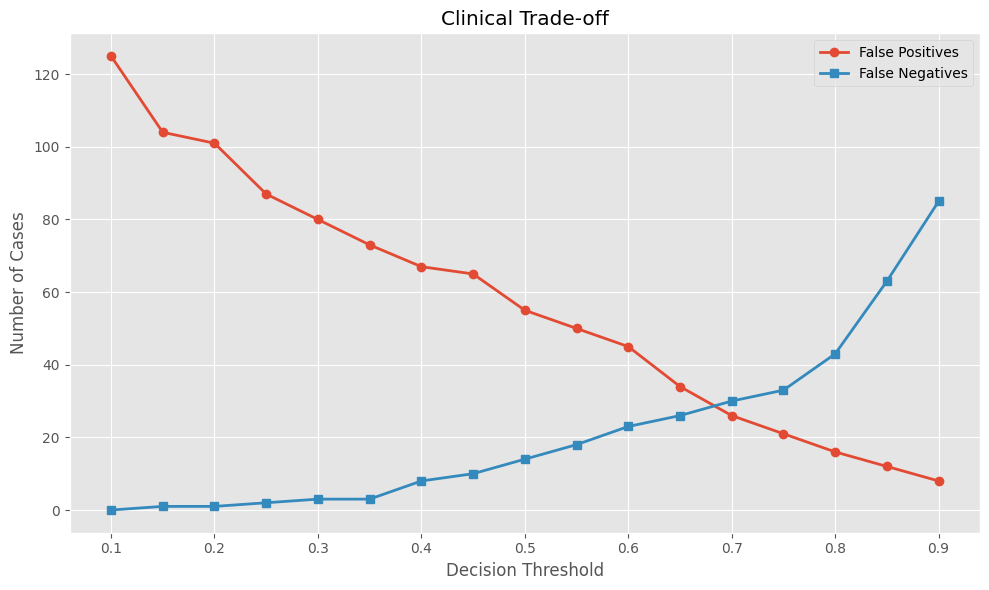

In [34]:
#####################################################
# False Positives vs False Negatives
#####################################################

plt.figure(figsize=(10,6))

plt.plot(
    results["Threshold"],
    results["False Positives"],
    marker="o",
    linewidth=2,
    label="False Positives"
)

plt.plot(
    results["Threshold"],
    results["False Negatives"],
    marker="s",
    linewidth=2,
    label="False Negatives"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Number of Cases")

plt.title("Clinical Trade-off")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

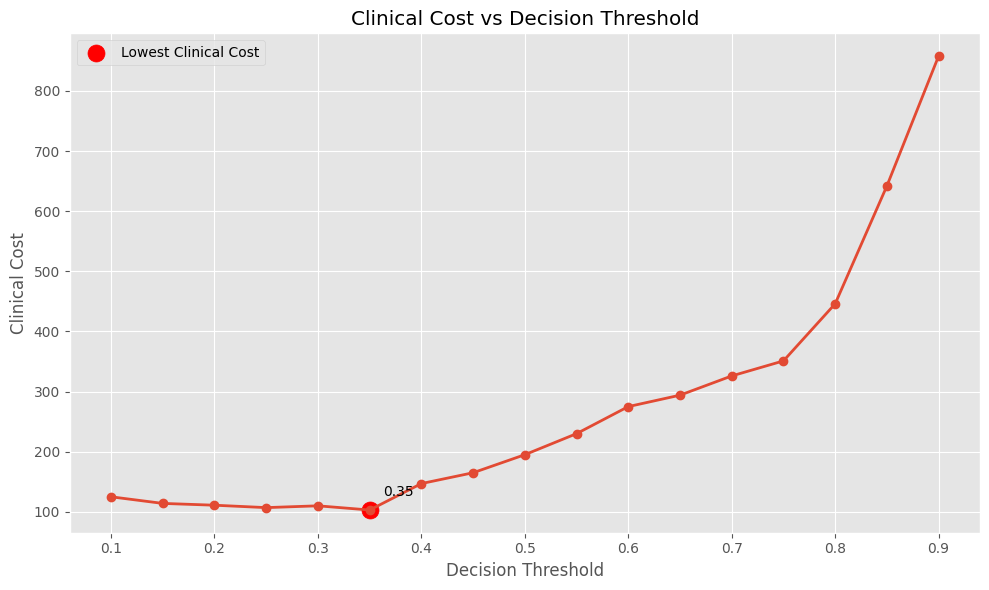

In [35]:
#####################################################
# Clinical Cost Curve
#####################################################

plt.figure(figsize=(10,6))

plt.plot(
    results["Threshold"],
    results["Clinical Cost"],
    marker="o",
    linewidth=2
)

best_threshold = best_cost["Threshold"]
best_value = best_cost["Clinical Cost"]

plt.scatter(
    best_threshold,
    best_value,
    s=150,
    color="red",
    label="Lowest Clinical Cost"
)

plt.annotate(
    f"{best_threshold:.2f}",
    (best_threshold, best_value),
    xytext=(10,10),
    textcoords="offset points"
)

plt.xlabel("Decision Threshold")

plt.ylabel("Clinical Cost")

plt.title("Clinical Cost vs Decision Threshold")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

In [36]:
print("="*60)
print("LOWEST CLINICAL COST")
print("="*60)

display(best_cost.to_frame().T.round(4))

LOWEST CLINICAL COST


,Threshold,Accuracy,Precision,Recall,F1 Score,Sensitivity,Specificity,False Positives,False Negatives,Clinical Cost
5,0.35,0.8782,0.8413,0.9923,0.9106,0.9923,0.688,73.0,3.0,103.0


In [ ]:

Threshold	Accuracy	Precision	Recall	F1 Score	Sensitivity	Specificity	False Positives	False Negatives	Clinical Cost
5	0.35	0.8782	0.8413	0.9923	0.9106	0.9923	0.688	73.0	3.0	103.0
